# Neural Earth Fields: starter notebook

Train a model that maps longitude/latitude to one of 11 [ESA WorldCover](https://esa-worldcover.org) land-cover classes. Two scores:

- **Most Efficient Overfitter:** memorize every point of a 5 km grid with as few stored values as possible. Efficiency score S = P + E², with P the stored values in your ONNX file and E the misclassified points; lower is better, exact fits (E = 0) rank first.
- **Overparameterized Interpolator:** accuracy at held-out locations, with no penalty on model size; higher is better.

This notebook trains a simple baseline, a Wrap encoder + MLP, exports it to ONNX and computes both scores.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neuralearthfields/neuralearthfields-starter/blob/main/starter.ipynb)

## Setup

Locally: `uv sync`, then `uv run jupyter lab`. In Colab: pick a GPU runtime; the cell below installs the missing packages.

In [1]:
import subprocess
import sys

if "google.colab" in sys.modules:
    packages = ["lightning", "torchmetrics", "onnx", "onnxscript", "pyarrow"]
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *packages], check=True
    )

In [2]:
import copy
import csv
import hashlib
import math
import shutil
import urllib.request
import zipfile
from pathlib import Path

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import onnx
import pyarrow.compute as pc
import pyarrow.parquet as pq
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from lightning.pytorch.loggers import CSVLogger
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchmetrics.classification import MulticlassAccuracy


class Config:
    data = Path("data")
    output = Path("outputs")
    checkpoints = Path("checkpoints")  # trained models are reused across runs
    retrain = False  # True ignores saved checkpoints
    external_weights = False  # True: weights in a separate model.onnx.data file
    input_dim, hidden_dim, output_dim = 992, 496, 992  # ~1M parameters
    batch_size = 4096
    train_steps = 5000
    eval_every = 250
    learning_rate = 1e-3
    seed = 0


cfg = Config()
cfg.output.mkdir(parents=True, exist_ok=True)
cfg.checkpoints.mkdir(parents=True, exist_ok=True)
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(cfg.seed)
torch.set_float32_matmul_precision("high")
print(device)

mps


## Data

The training file holds WorldCover classes at the 5.5 million points of a 5 km HEALPix grid over land (34 MB, downloaded once). The small test file holds 2,655 random held-out points, used to monitor training and for the second score.

5,504,940 training points, 2,655 test points


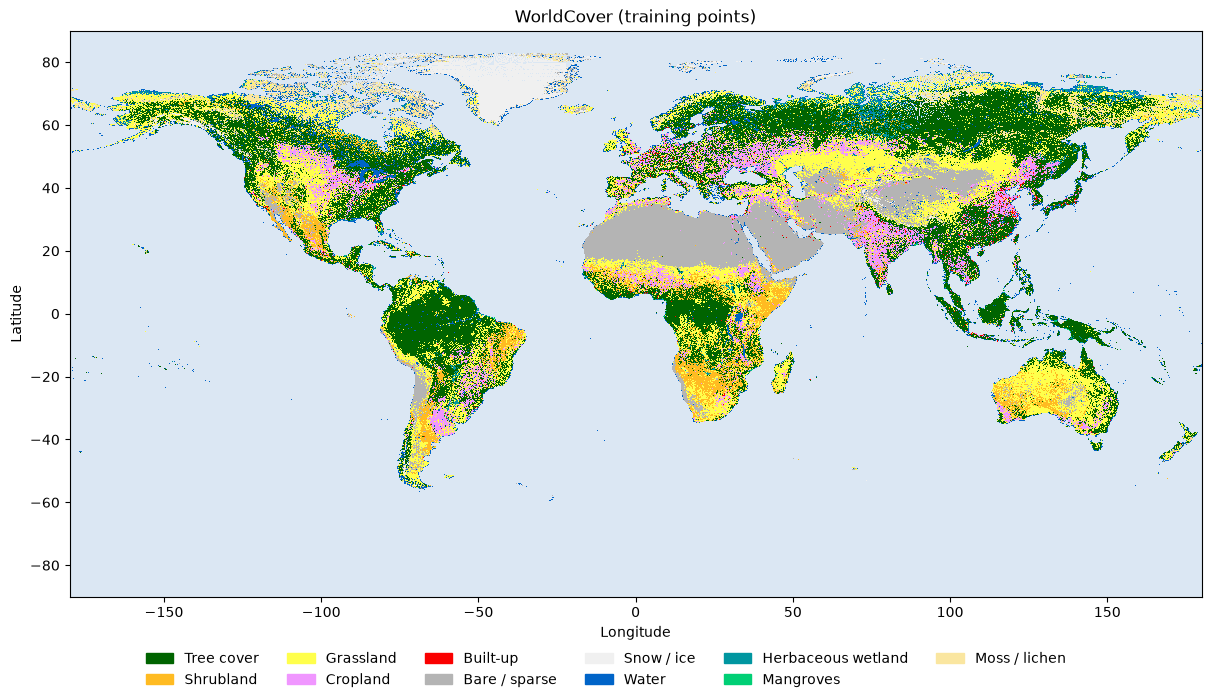

In [3]:
# WorldCover code -> (name, colour).
WORLDCOVER = {
    10: ("Tree cover", "#006400"),
    20: ("Shrubland", "#ffbb22"),
    30: ("Grassland", "#ffff4c"),
    40: ("Cropland", "#f096ff"),
    50: ("Built-up", "#fa0000"),
    60: ("Bare / sparse", "#b4b4b4"),
    70: ("Snow / ice", "#f0f0f0"),
    80: ("Water", "#0064c8"),
    90: ("Herbaceous wetland", "#0096a0"),
    95: ("Mangroves", "#00cf75"),
    100: ("Moss / lichen", "#fae6a0"),
}
DRIVE_IDS = {  # Google Drive file ids
    "healpix_5km_worldcover.parquet": "1cJYy7f52VWs19yz3fgNGJWWvh5hzZgb_",
    "worldcover_test.parquet": "1IwcpjBHjRiXJq0ennAErxP5hMbNk8wT-",
}


class WorldCoverDataset(Dataset):
    """(lon, lat) points with WorldCover class indices."""

    class_codes = np.array(list(WORLDCOVER), dtype="uint8")

    def __init__(self, path):
        self.path = Path(path)
        self.download()
        table = pq.read_table(self.path, columns=["worldcover", "geometry"])
        lon = pc.struct_field(table["geometry"], "x").to_numpy()
        lat = pc.struct_field(table["geometry"], "y").to_numpy()
        codes = table["worldcover"].to_numpy()
        self.coords = torch.from_numpy(np.column_stack((lon, lat)).astype("float32"))
        self.targets = torch.from_numpy(np.searchsorted(self.class_codes, codes))

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.coords[index], self.targets[index]

    def download(self):
        if self.path.exists():
            return
        self.path.parent.mkdir(parents=True, exist_ok=True)
        print(f"Downloading {self.path.name}")
        url = (
            "https://drive.usercontent.google.com/download"
            f"?id={DRIVE_IDS[self.path.name]}&export=download&confirm=t"
        )
        partial = self.path.with_suffix(".part")
        urllib.request.urlretrieve(url, partial)
        if partial.read_bytes()[:4] != b"PAR1":  # e.g. a Google sign-in page
            partial.unlink()
            raise RuntimeError(f"{url} did not return a parquet file; is it shared?")
        partial.rename(self.path)


train_data = WorldCoverDataset(cfg.data / "healpix_5km_worldcover.parquet")
test_data = WorldCoverDataset(cfg.data / "worldcover_test.parquet")
train_loader = DataLoader(train_data, batch_size=cfg.batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=cfg.batch_size)
class_names = [name for name, _ in WORLDCOVER.values()]
num_classes = len(class_names)
print(f"{len(train_data):,} training points, {len(test_data):,} test points")

cmap = ListedColormap([color for _, color in WORLDCOVER.values()])
cmap.set_bad("#dbe7f3")  # no data (ocean), distinct from snow / ice
legend = [Patch(color=color, label=name) for name, color in WORLDCOVER.values()]


def plot_map(ax, coords, labels, title):
    """Draw labelled points into a 0.1° longitude/latitude image."""
    cols = ((coords[:, 0] + 180) * 10).long().clamp(0, 3599)
    rows = ((90 - coords[:, 1]) * 10).long().clamp(0, 1799)
    image = torch.full((1800, 3600), -1)
    image[rows, cols] = labels
    ax.imshow(
        np.ma.masked_less(image.numpy(), 0),
        cmap=cmap,
        vmin=-0.5,
        vmax=num_classes - 0.5,
        extent=(-180, 180, -90, 90),
        interpolation="nearest",
    )
    ax.set(title=title, xlabel="Longitude", ylabel="Latitude")


fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
plot_map(ax, train_data.coords, train_data.targets, "WorldCover (training points)")
fig.legend(handles=legend, loc="outside lower center", ncol=6, frameon=False)
plt.show()

## Model

Wrap turns longitude/latitude into sine/cosine features; an MLP maps them to class logits.

In [4]:
class Wrap(nn.Module):
    def forward(self, coords):
        # [lon, lat] in degrees -> [cos(lon), sin(lon), cos(lat), sin(lat)]
        radians = coords * (torch.pi / 180)
        return torch.stack((radians.cos(), radians.sin()), dim=-1).flatten(1)


model = nn.Sequential(
    Wrap(),
    nn.Linear(4, cfg.input_dim),
    nn.ReLU(),
    nn.Linear(cfg.input_dim, cfg.hidden_dim),
    nn.ReLU(),
    nn.Linear(cfg.hidden_dim, cfg.output_dim),
    nn.ReLU(),
    nn.Linear(cfg.output_dim, num_classes),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

1,001,435 parameters


## Training

A trained model is saved to `checkpoints/` and loaded on later runs with the same model and settings. Set `retrain = True` to train again.

Loading checkpoints/wrap_mlp_ead600b7.pt


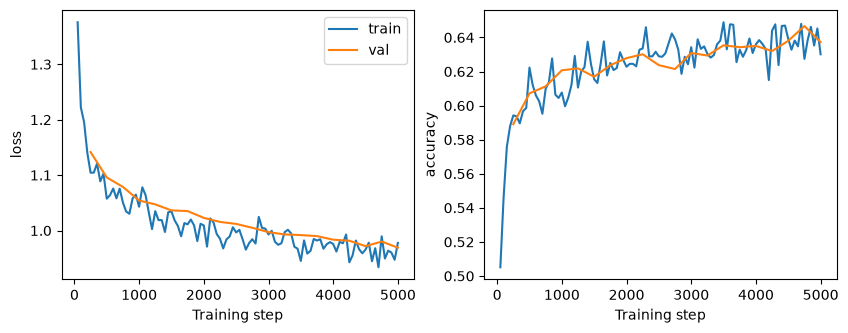

In [5]:
class LandCoverTask(L.LightningModule):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.train_accuracy = MulticlassAccuracy(num_classes, average="micro")
        self.val_accuracy = MulticlassAccuracy(num_classes, average="micro")

    def training_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        loss = F.cross_entropy(logits, target)
        self.train_accuracy(logits, target)
        self.log_dict({"train_loss": loss, "train_accuracy": self.train_accuracy})
        return loss

    def validation_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        self.val_accuracy(logits, target)
        self.log_dict(
            {
                "val_loss": F.cross_entropy(logits, target),
                "val_accuracy": self.val_accuracy,
            }
        )

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=cfg.learning_rate)


# The checkpoint name changes when the model or a training setting changes.
settings = repr(model) + repr(
    (cfg.train_steps, cfg.batch_size, cfg.learning_rate, cfg.seed)
)
checkpoint = (
    cfg.checkpoints / f"wrap_mlp_{hashlib.sha1(settings.encode()).hexdigest()[:8]}.pt"
)
history = checkpoint.with_suffix(".csv")

if checkpoint.exists() and not cfg.retrain:
    print(f"Loading {checkpoint}")
    model.load_state_dict(torch.load(checkpoint, map_location=device))
else:
    logger = CSVLogger(cfg.output, name="wrap_mlp")
    trainer = L.Trainer(
        accelerator=device.type,
        devices=1,
        max_steps=cfg.train_steps,
        val_check_interval=cfg.eval_every,
        check_val_every_n_epoch=None,
        log_every_n_steps=50,
        num_sanity_val_steps=0,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=logger,
    )
    trainer.fit(LandCoverTask(model), train_loader, test_loader)
    torch.save(model.state_dict(), checkpoint)
    shutil.copy(Path(logger.log_dir) / "metrics.csv", history)
model.to(device).eval()

with history.open() as stream:
    log = list(csv.DictReader(stream))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    for split in ["train", "val"]:
        values = [
            (int(r["step"]), float(r[f"{split}_{metric}"]))
            for r in log
            if r[f"{split}_{metric}"]
        ]
        ax.plot(*zip(*values), label=split)
    ax.set(xlabel="Training step", ylabel=metric)
axes[0].legend()
plt.show()

## Predictions

The model's class at every training point, below the ground truth.

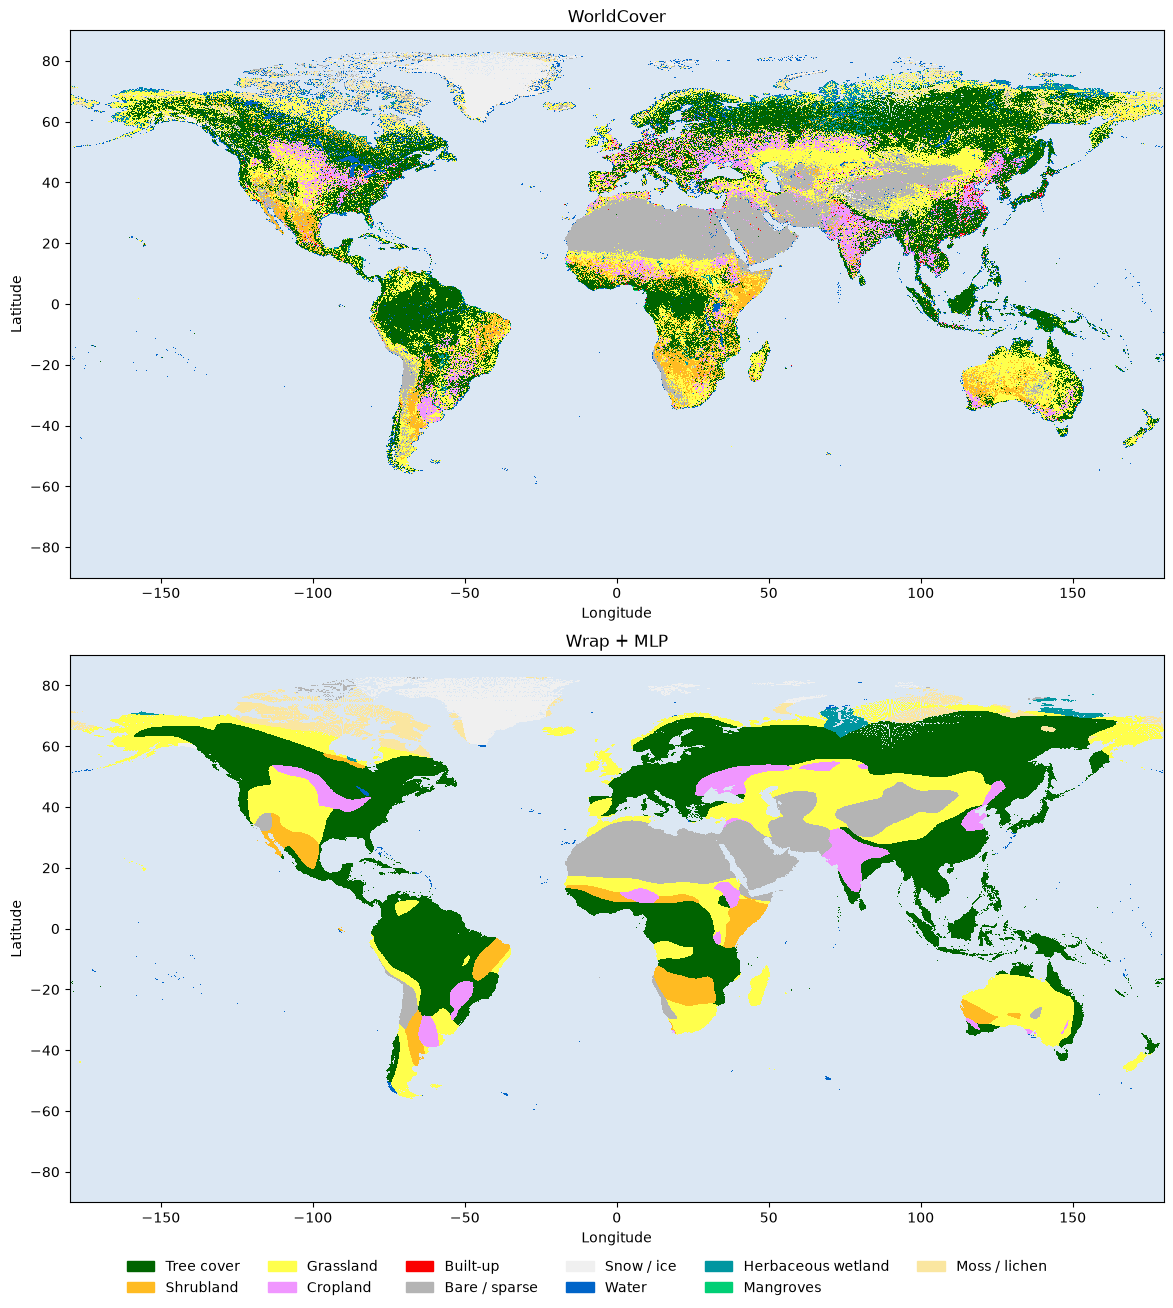

In [6]:
@torch.inference_mode()
def predict(network, coords, chunk_size=2**18):
    """Class index for every (lon, lat) row, computed in batches."""
    return torch.cat(
        [
            network(chunk.to(device)).argmax(1).cpu()
            for chunk in coords.split(chunk_size)
        ]
    )


train_predictions = predict(model, train_data.coords)
fig, axes = plt.subplots(2, 1, figsize=(12, 13), layout="constrained")
plot_map(axes[0], train_data.coords, train_data.targets, "WorldCover")
plot_map(axes[1], train_data.coords, train_predictions, "Wrap + MLP")
fig.legend(handles=legend, loc="outside lower center", ncol=6, frameon=False)
plt.show()

## Export to ONNX

Your model is an ONNX file: input `coords` float32 `[batch, 2]` (longitude, latitude in degrees), output `logits` `[batch, 11]`. The next cell exports it and packs `outputs/submission.zip`, the file you upload to the competition. The ZIP holds `model.onnx` and, only if `external_weights = True` (for very large models), the matching `model.onnx.data` weights file, both at the ZIP root.

In [7]:
program = torch.onnx.export(
    copy.deepcopy(model).cpu().eval(),
    (torch.zeros(2, 2),),
    input_names=["coords"],
    output_names=["logits"],
    dynamic_shapes=({0: torch.export.Dim("batch", min=1)},),
    dynamo=True,
    external_data=cfg.external_weights,
)
program.save(cfg.output / "model.onnx", external_data=cfg.external_weights)
if not cfg.external_weights:  # drop weights left over from an earlier run
    (cfg.output / "model.onnx.data").unlink(missing_ok=True)

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


In [ ]:
# Package the submission: files at the ZIP root, stored (uncompressed), nothing else.
files = ["model.onnx"] + (["model.onnx.data"] if cfg.external_weights else [])
graph = onnx.load(cfg.output / "model.onnx", load_external_data=False).graph
assert [i.name for i in graph.input] == ["coords"]
assert [o.name for o in graph.output] == ["logits"]
with zipfile.ZipFile(cfg.output / "submission.zip", "w", zipfile.ZIP_STORED) as archive:
    for name in files:
        archive.write(cfg.output / name, arcname=name)
size = (cfg.output / "submission.zip").stat().st_size
print(f"Wrote {cfg.output / 'submission.zip'} ({size / 1e6:.1f} MB): {', '.join(files)}")

## Score 1: Most Efficient Overfitter

E counts misclassified points over the whole 5 km grid; P counts every stored value in the ONNX file. Two references for comparison: predicting the most common class everywhere, and storing one value per point.

In [8]:
def stored_values(path):
    """Numbers stored in an ONNX file: weight tensors plus constant tensors in nodes."""
    graph = onnx.load(path, load_external_data=False).graph
    tensors = list(graph.initializer) + [
        a.t
        for n in graph.node
        for a in n.attribute
        if a.type == onnx.AttributeProto.TENSOR
    ]
    return sum(math.prod(t.dims) for t in tensors)


points = len(train_data)
rows = {
    "Wrap + MLP": (
        stored_values(cfg.output / "model.onnx"),
        int((train_predictions != train_data.targets).sum()),
    ),
    "Majority class (reference)": (
        1,
        points - int(torch.bincount(train_data.targets).max()),
    ),
    "Full lookup (reference)": (points, 0),
}
table = [
    "| Model | Stored values P | Mistakes E | Efficiency score P + E² | Accuracy |",
    "|---|--:|--:|--:|--:|",
]
for name, (p, e) in rows.items():
    table.append(f"| {name} | {p:,} | {e:,} | {p + e**2:,} | {1 - e / points:.4f} |")
display(Markdown("\n".join(table)))

| Model | Stored values P | Mistakes E | Efficiency score P + E² | Accuracy |
|---|--:|--:|--:|--:|
| Wrap + MLP | 1,001,439 | 1,985,414 | 3,941,869,752,835 | 0.6393 |
| Majority class (reference) | 1 | 3,726,802 | 13,889,053,147,205 | 0.3230 |
| Full lookup (reference) | 5,504,940 | 0 | 5,504,940 | 1.0000 |

## Score 2: Overparameterized Interpolator

Accuracy at locations the model was not trained on, with no model-size penalty: large models should interpolate well between training points. This notebook estimates it on the random test points; the final evaluation runs separately, on held-out locations of the 1 km grid.

References: 1-nearest neighbour copies the class of the closest training point; majority class predicts the most common class everywhere.

In [9]:
@torch.inference_mode()
def nearest_neighbour(train, test, chunk_size=16):
    """Class of the closest training point (on the sphere) for every test point."""

    def unit_vectors(coords):
        lon, lat = torch.deg2rad(coords.double()).T
        xyz = torch.stack((lat.cos() * lon.cos(), lat.cos() * lon.sin(), lat.sin()), 1)
        return xyz.float().to(device)

    reference = unit_vectors(train.coords)
    nearest = [
        # Direct differences keep metre precision (dot products lose it in float32).
        ((query[:, None] - reference) ** 2).sum(-1).argmin(1).cpu()
        for query in unit_vectors(test.coords).split(chunk_size)
    ]
    return train.targets[torch.cat(nearest)]


majority = int(torch.bincount(train_data.targets).argmax())
rows = {
    "Wrap + MLP": float(
        (predict(model, test_data.coords) == test_data.targets).float().mean()
    ),
    "1-nearest neighbour (reference)": float(
        (nearest_neighbour(train_data, test_data) == test_data.targets).float().mean()
    ),
    "Majority class (reference)": float((test_data.targets == majority).float().mean()),
}
table = ["| Model | Test accuracy |", "|---|--:|"]
table += [f"| {name} | {accuracy:.4f} |" for name, accuracy in rows.items()]
display(Markdown("\n".join(table)))

| Model | Test accuracy |
|---|--:|
| Wrap + MLP | 0.6373 |
| 1-nearest neighbour (reference) | 0.6900 |
| Majority class (reference) | 0.3330 |

## Data

ESA WorldCover 10 m 2021 v200, © ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).